# Sesión de clase 14 · Ejercicio 2: Ontología de la Tienda Virtual y RAG determinista

**Contexto:** el RAG del Ejercicio 1 responde bien cuando la respuesta está escrita en un documento,
pero falla cuando hay que **contar, agregar, ordenar o cruzar relaciones** ("¿qué país vende más?",
"¿qué productos recibieron reseñas negativas de clientes de Chile?"). Para eso hace falta conocer la
**estructura** de los datos: qué entidades hay y cómo se relacionan. Eso es una **ontología**.

Sobre la ontología se construye un **RAG determinista**: la pregunta se traduce a una consulta
exacta (SPARQL) y la respuesta se arma con una plantilla, sin generación libre. Misma pregunta →
misma respuesta, con la consulta como evidencia.

**Datos** (`../data/`): `productos.csv`, `clientes.csv`, `ordenes.csv`, `orden_items.csv`,
`resenas_entrega.csv`, `comentarios.csv` y el banco `preguntas_prueba.csv`.

**Etapas:** Parte A — modelar (TBox) · poblar (ABox) · SPARQL · inferencia · validación SHACL ·
**comparación sin vs. con ontología**. Parte B — router de intenciones · plantillas SPARQL ·
respuestas con plantilla · *fallback* a RAG · **comparación RAG generativo vs. determinista**.

## 0. Configuración

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")
import json, re, sys, time, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import chromadb
from chromadb.utils import embedding_functions
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
from rdflib import Graph, Literal, Namespace, URIRef
from rdflib.namespace import RDF, RDFS, OWL, XSD
from pyshacl import validate

sys.path.append("..")
import comparacion as cmp
import transformers; transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()

DATA, ONTO, BDV = Path("../data"), Path("../ontologia"), Path("../bdv")
ONTO.mkdir(exist_ok=True)
MODELO_EMB = "paraphrase-multilingual-MiniLM-L12-v2"
MODELO_LLM = "Qwen/Qwen2.5-0.5B-Instruct"
pd.set_option("display.max_colwidth", 110)

W1124 16:51:03.295000 28188 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
productos = pd.read_csv(DATA / "productos.csv")
clientes = pd.read_csv(DATA / "clientes.csv")[["id", "ciudad", "pais"]]   # sin DNI, nombre ni correo
ordenes = pd.read_csv(DATA / "ordenes.csv")
items = pd.read_csv(DATA / "orden_items.csv")
resenas = pd.read_csv(DATA / "resenas_entrega.csv")
testimonios = pd.read_csv(DATA / "comentarios.csv")
banco = cmp.cargar_banco()
{n: len(df) for n, df in [("productos", productos), ("clientes", clientes), ("ordenes", ordenes),
                         ("orden_items", items), ("resenas_entrega", resenas), ("testimonios", testimonios)]}

{'productos': 90,
 'clientes': 120,
 'ordenes': 300,
 'orden_items': 900,
 'resenas_entrega': 110,
 'testimonios': 135}

# Parte A · Ontología

## 1. Conceptos

Una **ontología** es un modelo explícito de un dominio: qué **clases** de cosas existen, qué
**propiedades** las relacionan y qué reglas cumplen. Se expresa en **RDF**, donde todo es una
**tripleta** *(sujeto, predicado, objeto)*:

```
tv:producto_67   rdf:type           tv:Producto .
tv:producto_67   tv:perteneceA      tv:subcat_Drones .
tv:producto_67   tv:precio          6999 .
```

| Concepto | Qué es | En la tienda |
|---|---|---|
| **Clase** | tipo de entidad | `Producto`, `Cliente`, `Orden`, `ResenaEntrega` |
| **Propiedad de objeto** | relación entre entidades | `Orden —realizadaPor→ Cliente` |
| **Propiedad de datos** | atributo con un valor literal | `Producto —precio→ 6999` |
| **TBox** | el esquema (clases, propiedades, jerarquías) | `ontologia/tienda.ttl` |
| **ABox** | los hechos (instancias) | los 90 productos, 300 órdenes… |
| **URI** | identificador global de cada recurso | `http://tienda.local/ontologia#Producto` |

Las clases y propiedades salen de lo que se aprendió al **scrapear** la tienda: las páginas de
producto (categoría, subcategoría, precio, stock), el sitemap de clientes, las órdenes de la API y las
reseñas post-compra ligadas a una orden y a un producto.

```mermaid
graph LR
  Orden -- realizadaPor --> Cliente
  Orden -- contiene --> Producto
  Cliente -- resideEn --> Pais
  Producto -- perteneceA --> Subcategoria
  Subcategoria -- subcategoriaDe --> Categoria
  ResenaEntrega -- sobreProducto --> Producto
  ResenaEntrega -- sobreOrden --> Orden
  Resena -- escritaPor --> Cliente
  ResenaEntrega -. subClassOf .-> Resena
  Testimonio -. subClassOf .-> Resena
```

## 2. TBox: el esquema

In [3]:
TV = Namespace("http://tienda.local/ontologia#")

def nuevo_grafo():
    g = Graph()
    g.bind("tv", TV); g.bind("owl", OWL)
    return g

tbox = nuevo_grafo()
tbox.add((URIRef("http://tienda.local/ontologia"), RDF.type, OWL.Ontology))

CLASES = {
    "Producto": "Artículo del catálogo de la tienda",
    "Categoria": "Categoría principal del catálogo (9 en total)",
    "Subcategoria": "Subdivisión de una categoría",
    "Cliente": "Persona que compra en la tienda",
    "Pais": "País de residencia del cliente",
    "Orden": "Compra realizada por un cliente",
    "Resena": "Opinión escrita por un cliente",
    "ResenaEntrega": "Reseña post-compra sobre la entrega de un producto",
    "Testimonio": "Comentario general sobre la tienda",
}
for clase, comentario in CLASES.items():
    tbox.add((TV[clase], RDF.type, OWL.Class))
    tbox.add((TV[clase], RDFS.label, Literal(clase, lang="es")))
    tbox.add((TV[clase], RDFS.comment, Literal(comentario, lang="es")))
tbox.add((TV.ResenaEntrega, RDFS.subClassOf, TV.Resena))
tbox.add((TV.Testimonio, RDFS.subClassOf, TV.Resena))

PROPIEDADES_OBJETO = [  # (propiedad, dominio, rango)
    ("perteneceA", "Producto", "Subcategoria"), ("subcategoriaDe", "Subcategoria", "Categoria"),
    ("resideEn", "Cliente", "Pais"), ("realizadaPor", "Orden", "Cliente"),
    ("contiene", "Orden", "Producto"), ("escritaPor", "Resena", "Cliente"),
    ("sobreProducto", "ResenaEntrega", "Producto"), ("sobreOrden", "ResenaEntrega", "Orden"),
]
PROPIEDADES_DATOS = [
    ("nombre", "Producto", XSD.string), ("codigo", "Producto", XSD.string),
    ("descripcion", "Producto", XSD.string), ("precio", "Producto", XSD.decimal),
    ("stock", "Producto", XSD.integer), ("calificacionPromedio", "Producto", XSD.decimal),
    ("ciudad", "Cliente", XSD.string), ("numero", "Orden", XSD.string),
    ("fecha", None, XSD.date), ("total", "Orden", XSD.decimal),
    ("calificacion", "Resena", XSD.integer), ("texto", "Resena", XSD.string),
]
for prop, dom, rango in PROPIEDADES_OBJETO:
    tbox.add((TV[prop], RDF.type, OWL.ObjectProperty))
    tbox.add((TV[prop], RDFS.domain, TV[dom])); tbox.add((TV[prop], RDFS.range, TV[rango]))
for prop, dom, rango in PROPIEDADES_DATOS:
    tbox.add((TV[prop], RDF.type, OWL.DatatypeProperty)); tbox.add((TV[prop], RDFS.range, rango))
    if dom:
        tbox.add((TV[prop], RDFS.domain, TV[dom]))

tbox.serialize(ONTO / "tienda.ttl", format="turtle")
print(f"TBox: {len(tbox)} tripletas → {ONTO / 'tienda.ttl'}\n")
print((ONTO / "tienda.ttl").read_text()[:1400])

TBox: 89 tripletas → ../ontologia/tienda.ttl

@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix tv: <http://tienda.local/ontologia#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<http://tienda.local/ontologia> a owl:Ontology .

tv:Testimonio a owl:Class ;
    rdfs:label "Testimonio"@es ;
    rdfs:comment "Comentario general sobre la tienda"@es ;
    rdfs:subClassOf tv:Resena .

tv:calificacion a owl:DatatypeProperty ;
    rdfs:domain tv:Resena ;
    rdfs:range xsd:integer .

tv:calificacionPromedio a owl:DatatypeProperty ;
    rdfs:domain tv:Producto ;
    rdfs:range xsd:decimal .

tv:ciudad a owl:DatatypeProperty ;
    rdfs:domain tv:Cliente ;
    rdfs:range xsd:string .

tv:codigo a owl:DatatypeProperty ;
    rdfs:domain tv:Producto ;
    rdfs:range xsd:string .

tv:contiene a owl:ObjectProperty ;
    rdfs:domain tv:Orden ;
    rdfs:range tv:Producto .

tv:descripcion a owl:DatatypeProperty ;
    rdfs:domain tv:Pr

## 3. ABox: poblar la ontología con los datos scrapeados

Cada fila de cada CSV se convierte en un recurso con su URI y sus tripletas. Las claves foráneas
(`cliente_id`, `producto_id`, `orden_id`) se convierten en **relaciones explícitas**.

In [4]:
def slug(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    return re.sub(r"[^A-Za-z0-9]+", "_", "".join(c for c in texto if not unicodedata.combining(c))).strip("_")

def poblar(productos, clientes, ordenes, items, resenas, testimonios):
    g = nuevo_grafo()
    g += tbox
    for cat, sub in productos[["categoria", "subcategoria"]].drop_duplicates().itertuples(index=False):
        g.add((TV[f"cat_{slug(cat)}"], RDF.type, TV.Categoria)); g.add((TV[f"cat_{slug(cat)}"], RDFS.label, Literal(cat)))
        g.add((TV[f"sub_{slug(sub)}"], RDF.type, TV.Subcategoria)); g.add((TV[f"sub_{slug(sub)}"], RDFS.label, Literal(sub)))
        g.add((TV[f"sub_{slug(sub)}"], TV.subcategoriaDe, TV[f"cat_{slug(cat)}"]))
    for p in productos.itertuples():
        s = TV[f"producto_{p.id}"]
        g.add((s, RDF.type, TV.Producto)); g.add((s, RDFS.label, Literal(p.nombre)))
        g.add((s, TV.nombre, Literal(p.nombre))); g.add((s, TV.codigo, Literal(p.codigo)))
        g.add((s, TV.descripcion, Literal(p.descripcion)))
        g.add((s, TV.precio, Literal(p.precio, datatype=XSD.decimal)))
        g.add((s, TV.stock, Literal(int(p.stock))))
        g.add((s, TV.calificacionPromedio, Literal(p.calificacion_promedio, datatype=XSD.decimal)))
        g.add((s, TV.perteneceA, TV[f"sub_{slug(p.subcategoria)}"]))
    for c in clientes.itertuples():
        s = TV[f"cliente_{c.id}"]
        g.add((s, RDF.type, TV.Cliente)); g.add((s, TV.ciudad, Literal(c.ciudad)))
        g.add((s, TV.resideEn, TV[f"pais_{slug(c.pais)}"]))
        g.add((TV[f"pais_{slug(c.pais)}"], RDF.type, TV.Pais)); g.add((TV[f"pais_{slug(c.pais)}"], RDFS.label, Literal(c.pais)))
    for o in ordenes.itertuples():
        s = TV[f"orden_{o.id}"]
        g.add((s, RDF.type, TV.Orden)); g.add((s, TV.numero, Literal(o.numero)))
        g.add((s, TV.fecha, Literal(o.fecha, datatype=XSD.date)))
        g.add((s, TV.total, Literal(o.total, datatype=XSD.decimal)))
        g.add((s, TV.realizadaPor, TV[f"cliente_{o.cliente_id}"]))
    for it in items.itertuples():
        g.add((TV[f"orden_{it.orden_id}"], TV.contiene, TV[f"producto_{it.producto_id}"]))
    for r in resenas.itertuples():
        s = TV[f"resena_{r.id}"]
        g.add((s, RDF.type, TV.ResenaEntrega)); g.add((s, TV.calificacion, Literal(int(r.calificacion))))
        g.add((s, TV.fecha, Literal(r.fecha, datatype=XSD.date))); g.add((s, TV.texto, Literal(r.texto)))
        g.add((s, TV.escritaPor, TV[f"cliente_{r.cliente_id}"]))
        g.add((s, TV.sobreProducto, TV[f"producto_{r.producto_id}"])); g.add((s, TV.sobreOrden, TV[f"orden_{r.orden_id}"]))
    for t in testimonios.itertuples():
        s = TV[f"testimonio_{t.id}"]
        g.add((s, RDF.type, TV.Testimonio)); g.add((s, TV.calificacion, Literal(int(t.calificacion))))
        g.add((s, TV.fecha, Literal(t.fecha, datatype=XSD.date))); g.add((s, TV.texto, Literal(t.texto)))
        g.add((s, TV.escritaPor, TV[f"cliente_{t.cliente_id}"]))
    return g

g = poblar(productos, clientes, ordenes, items, resenas, testimonios)
g.serialize(ONTO / "tienda_poblada.ttl", format="turtle")
print(f"Grafo: {len(g):,} tripletas → {ONTO / 'tienda_poblada.ttl'}")

Grafo: 5,238 tripletas → ../ontologia/tienda_poblada.ttl


In [5]:
# Así se ve un producto en Turtle: todas sus tripletas
ficha = g.cbd(TV.producto_67); ficha.bind("tv", TV)
print(ficha.serialize(format="turtle"))

@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix tv: <http://tienda.local/ontologia#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

tv:producto_67 a tv:Producto ;
    rdfs:label "DJI Air 3" ;
    tv:calificacionPromedio 3.7 ;
    tv:codigo "PROD-067" ;
    tv:descripcion "Dron con doble camara gran angular y teleobjetivo, hasta 46 minutos de autonomia de vuelo y transmision de video a larga distancia. Incluye deteccion de obstaculos en las cuatro direcciones." ;
    tv:nombre "DJI Air 3" ;
    tv:perteneceA tv:sub_Drones ;
    tv:precio 6999.0 ;
    tv:stock 4 .




## 4. Consultas SPARQL

**SPARQL** es el lenguaje de consulta de RDF: se describe un **patrón de tripletas** con variables
(`?x`) y el motor devuelve todas las combinaciones que lo cumplen. Admite `FILTER`, `GROUP BY`,
agregados (`COUNT`, `AVG`, `SUM`) y caminos de propiedades (`/`, `*`).

In [6]:
PREFIJOS = "PREFIX tv: <http://tienda.local/ontologia#>\nPREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>\n"

def sparql(consulta, grafo=None, **parametros):
    """Ejecuta SPARQL y devuelve un DataFrame. Los parámetros se enlazan con initBindings (nunca concatenando texto)."""
    grafo = g if grafo is None else grafo
    enlaces = {k: (v if isinstance(v, (Literal, URIRef)) else Literal(v)) for k, v in parametros.items()}
    r = grafo.query(PREFIJOS + consulta, initBindings=enlaces)
    return pd.DataFrame([[v.toPython() if v is not None else None for v in fila] for fila in r],
                        columns=[str(v) for v in r.vars])

sparql("""
SELECT ?categoria (COUNT(?p) AS ?productos) (AVG(?precio) AS ?precio_medio)
WHERE { ?p a tv:Producto ; tv:precio ?precio ; tv:perteneceA/tv:subcategoriaDe/rdfs:label ?categoria . }
GROUP BY ?categoria ORDER BY DESC(?precio_medio)
""")

,categoria,productos,precio_medio
0,Laptops y Computadoras,10,5389
1,Televisores y Video,10,3699
2,Fotografia y Video,10,3134
3,Smartphones,10,2619
4,Electrodomesticos Inteligentes,10,1866
5,Wearables y Fitness,10,1839
6,Gaming y Consolas,10,1209
7,Audio,10,938
8,Accesorios y Componentes,10,245


In [7]:
# Ventas por país: Orden → realizadaPor → Cliente → resideEn → País
sparql("""
SELECT ?pais (COUNT(?o) AS ?ordenes) (SUM(?total) AS ?ventas)
WHERE { ?o a tv:Orden ; tv:total ?total ; tv:realizadaPor/tv:resideEn/rdfs:label ?pais . }
GROUP BY ?pais ORDER BY DESC(?ventas)
""")

,pais,ordenes,ventas
0,Peru,103,2011695.86
1,Chile,42,973372.56
2,Colombia,37,884112.64
3,Ecuador,37,721735.20
4,Argentina,32,665499.94
5,Uruguay,28,549718.34
6,Mexico,21,418566.06


In [8]:
# Pregunta relacional: productos con reseñas de entrega negativas (≤ 2★) de clientes de un país
CONSULTA_NEGATIVAS = """
SELECT ?producto ?calificacion ?texto
WHERE { ?r a tv:ResenaEntrega ; tv:calificacion ?calificacion ; tv:texto ?texto ;
           tv:sobreProducto/tv:nombre ?producto ; tv:escritaPor/tv:resideEn/rdfs:label ?pais .
        FILTER(?calificacion <= 2) }
ORDER BY ?calificacion
"""
sparql(CONSULTA_NEGATIVAS, pais="Chile")

,producto,calificacion,texto
0,OnePlus 12 256GB,1,El OnePlus 12 que recibi no coincidia con el color que habia pedido en el pedido original. Tuve que devolv...
1,Sennheiser Momentum 4,2,El segundo pedido de audifonos Sennheiser llego con retraso durante una fecha de alta demanda sin ninguna ...
2,Garmin Forerunner 265,2,El reloj Garmin llego con la correa de un color distinto al que aparecia en las fotos del producto. El equ...
3,HP Pavilion 15 Intel Core i5,2,La laptop HP llego con un dia de retraso adicional despues de que el courier reprogramara la entrega sin a...


## 5. Inferencia

La ontología permite **deducir** hechos que no están escritos en los datos.

### 5.1 Jerarquía de clases (`rdfs:subClassOf`)

Ninguna instancia fue declarada como `tv:Resena`: solo como `ResenaEntrega` o `Testimonio`. Pero
el esquema dice que ambas son subclases de `Resena`, así que un razonador RDFS infiere que **todas**
son reseñas. En SPARQL se expresa con el camino `rdf:type/rdfs:subClassOf*`.

In [9]:
sin_inferencia = sparql("SELECT (COUNT(?r) AS ?n) WHERE { ?r a tv:Resena }").n[0]
con_inferencia = sparql("SELECT (COUNT(?r) AS ?n) WHERE { ?r a/rdfs:subClassOf* tv:Resena }").n[0]
print(f"Reseñas declaradas directamente: {sin_inferencia} · inferidas por la jerarquía: {con_inferencia}")

Reseñas declaradas directamente: 0 · inferidas por la jerarquía: 245


### 5.2 Regla de negocio: producto en riesgo

Regla: *un producto está en riesgo si su calificación promedio es menor que 3 y tiene al menos una
reseña de entrega de 1–2★*. Con `CONSTRUCT` la regla genera **nuevas tripletas**
(`?p a tv:ProductoEnRiesgo`) que se agregan al grafo y quedan disponibles para cualquier consulta.

In [11]:
tbox.add((TV.ProductoEnRiesgo, RDF.type, OWL.Class)); tbox.add((TV.ProductoEnRiesgo, RDFS.subClassOf, TV.Producto))
tbox.add((TV.ProductoEnRiesgo, RDFS.comment, Literal("Producto con calificación < 3 y al menos una reseña de entrega negativa", lang="es")))
g += tbox

REGLA_RIESGO = PREFIJOS + """
CONSTRUCT { ?p a tv:ProductoEnRiesgo }
WHERE { ?p a tv:Producto ; tv:calificacionPromedio ?c . FILTER(?c < 3)
        FILTER EXISTS { ?r tv:sobreProducto ?p ; tv:calificacion ?cal . FILTER(?cal <= 2) } }
"""
inferidas = g.query(REGLA_RIESGO).graph
g += inferidas
print(f"Tripletas inferidas: {len(inferidas)}")
sparql("SELECT ?nombre ?calificacion WHERE { ?p a tv:ProductoEnRiesgo ; tv:nombre ?nombre ; tv:calificacionPromedio ?calificacion } ORDER BY ?calificacion")

Tripletas inferidas: 6


,nombre,calificacion
0,Samsung Galaxy A15 128GB,1.8
1,Sony Bravia X75L 65 pulgadas,2.0
2,HP Omen 16 RTX 4060,2.0
3,JBL Flip 6,2.8
4,TCL 50 pulgadas 4K Google TV,2.8
5,Xiaomi Redmi Note 13 Pro 256GB,2.8


In [12]:
g.serialize(ONTO / "tienda_poblada.ttl", format="turtle")     # se guarda con las inferencias (lo usa el MCP server)
tbox.serialize(ONTO / "tienda.ttl", format="turtle")
print(f"{len(g):,} tripletas guardadas")

5,247 tripletas guardadas


## 6. Validación con SHACL

**SHACL** describe *formas* (*shapes*) que los datos deben cumplir: cardinalidades, tipos, rangos.
Es el control de calidad de la ontología: detecta datos mal scrapeados **antes** de que lleguen al
asistente.

In [13]:
SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> .
@prefix tv: <http://tienda.local/ontologia#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

tv:ProductoShape a sh:NodeShape ; sh:targetClass tv:Producto ;
    sh:property [ sh:path tv:nombre ; sh:minCount 1 ; sh:maxCount 1 ] ;
    sh:property [ sh:path tv:precio ; sh:minCount 1 ; sh:minExclusive 0 ] ;
    sh:property [ sh:path tv:stock ; sh:datatype xsd:integer ; sh:minInclusive 0 ] ;
    sh:property [ sh:path tv:perteneceA ; sh:minCount 1 ; sh:class tv:Subcategoria ] .

tv:ResenaEntregaShape a sh:NodeShape ; sh:targetClass tv:ResenaEntrega ;
    sh:property [ sh:path tv:calificacion ; sh:minInclusive 1 ; sh:maxInclusive 5 ] ;
    sh:property [ sh:path tv:sobreProducto ; sh:minCount 1 ; sh:maxCount 1 ; sh:class tv:Producto ] .
"""
shapes = Graph().parse(data=SHAPES, format="turtle")
conforma, _, _ = validate(g, shacl_graph=shapes)
print("¿Los datos scrapeados cumplen las formas?", conforma)

¿Los datos scrapeados cumplen las formas? True


## 7. Comparación: sin ontología vs. con ontología

### 7.1 Una pregunta relacional

*"¿Qué productos recibieron reseñas de entrega negativas de clientes de Chile?"* exige recorrer
**reseña → cliente → país** y **reseña → producto**. Se resuelve de tres formas:

In [14]:
pregunta = banco.set_index("id").pregunta[8]

# (a) Sin ontología, con pandas: hay que conocer las columnas y encadenar los JOIN a mano
t0 = time.perf_counter()
con_pandas = (resenas[resenas.calificacion <= 2]
              .merge(clientes, left_on="cliente_id", right_on="id")
              .merge(productos[["id", "nombre"]], left_on="producto_id", right_on="id")
              .query("pais == 'Chile'").nombre.tolist())
t_pandas = time.perf_counter() - t0

# (b) Sin ontología, con RAG semántico (Ejercicio 1): recupera reseñas parecidas a la pregunta
emb_fn = embedding_functions.SentenceTransformerEmbeddingFunction(model_name=MODELO_EMB)
col_resenas = chromadb.PersistentClient(path=str(BDV)).get_collection("resenas", embedding_function=emb_fn)
recuperadas = col_resenas.query(query_texts=[pregunta], n_results=7)
con_rag = sorted({m["producto"] for m, d in zip(recuperadas["metadatas"][0], recuperadas["documents"][0])
                  if m["pais"] == "Chile" and m["calificacion"] <= 2})

# (c) Con ontología: una consulta SPARQL que expresa el recorrido
t0 = time.perf_counter()
con_sparql = sparql(CONSULTA_NEGATIVAS, pais="Chile").producto.tolist()
t_sparql = time.perf_counter() - t0

pd.DataFrame({
    "enfoque": ["pandas (JOIN manual)", "RAG semántico (top-7)", "ontología + SPARQL"],
    "productos encontrados": [sorted(set(con_pandas)), con_rag, sorted(set(con_sparql))],
    "cantidad": [len(set(con_pandas)), len(con_rag), len(set(con_sparql))],
    "qué hay que saber": ["nombres de columnas y claves foráneas de 3 CSV", "nada, pero no garantiza cobertura",
                          "el vocabulario de la ontología (tv:escritaPor, tv:resideEn…)"],
})

,enfoque,productos encontrados,cantidad,qué hay que saber
0,pandas (JOIN manual),"[Garmin Forerunner 265, HP Pavilion 15 Intel Core i5, OnePlus 12 256GB, Sennheiser Momentum 4]",4,nombres de columnas y claves foráneas de 3 CSV
1,RAG semántico (top-7),"[OnePlus 12 256GB, Sennheiser Momentum 4]",2,"nada, pero no garantiza cobertura"
2,ontología + SPARQL,"[Garmin Forerunner 265, HP Pavilion 15 Intel Core i5, OnePlus 12 256GB, Sennheiser Momentum 4]",4,"el vocabulario de la ontología (tv:escritaPor, tv:resideEn…)"


Pandas y SPARQL coinciden (son exactos); el RAG solo ve las 7 reseñas más parecidas a la pregunta y
se pierde casos. La diferencia entre pandas y la ontología no es el resultado sino **dónde vive el
conocimiento**: en pandas, la relación *reseña → cliente → país* está en el código de quien hizo el
JOIN; en la ontología está declarada en el modelo y cualquiera (una persona, un LLM, un MCP server)
puede descubrirla y reutilizarla.

### 7.2 Calidad de datos: un registro mal scrapeado

Se simula un error típico de scraping: un producto con precio negativo y sin subcategoría, y una
reseña con calificación 7 que no apunta a ningún producto.

In [15]:
productos_mal = pd.concat([productos, pd.DataFrame([{"id": 999, "codigo": "PROD-999", "nombre": "Producto mal scrapeado",
    "descripcion": "", "categoria": None, "subcategoria": None, "precio": -10, "stock": 3,
    "calificacion_promedio": 4.0, "total_resenas": 0, "url": ""}])], ignore_index=True)
resenas_mal = pd.concat([resenas, pd.DataFrame([{"id": 9999, "orden_id": 1, "cliente_id": 1, "producto_id": 12345,
    "calificacion": 7, "fecha": "2026-01-01", "texto": "Excelente"}])], ignore_index=True)

# Sin ontología: pandas carga y calcula sin quejarse
print("pandas → precio mínimo:", productos_mal.precio.min(), "· calificación máxima:", resenas_mal.calificacion.max(), "(ningún error)")

# Con ontología: SHACL detecta cada violación
g_mal = poblar(productos_mal.fillna({"subcategoria": "", "categoria": ""}), clientes, ordenes, items, resenas_mal, testimonios)
g_mal.remove((TV.producto_999, TV.perteneceA, None))     # el producto quedó sin subcategoría
conforma, reporte, _ = validate(g_mal, shacl_graph=shapes)
SH = Namespace("http://www.w3.org/ns/shacl#")
print("SHACL → ¿conforma?", conforma)
pd.DataFrame([{"nodo": str(reporte.value(v, SH.focusNode)).split("#")[-1],
               "propiedad": str(reporte.value(v, SH.resultPath)).split("#")[-1],
               "problema": str(reporte.value(v, SH.resultMessage))}
              for v in reporte.subjects(RDF.type, SH.ValidationResult)])

pandas → precio mínimo: -10 · calificación máxima: 7 (ningún error)
SHACL → ¿conforma? False


,nodo,propiedad,problema
0,producto_999,precio,"Value is not > Literal(""0"", datatype=xsd:integer)"
1,producto_999,perteneceA,Less than 1 values on tv:producto_999->tv:perteneceA
2,resena_9999,calificacion,"Value is not <= Literal(""5"", datatype=xsd:integer)"
3,resena_9999,sobreProducto,Value does not have class tv:Producto


# Parte B · RAG determinista

## 8. Idea

Un **RAG determinista** no le pide al LLM que *escriba* los hechos. Separa el problema en pasos
reproducibles:

```mermaid
graph LR
  P[Pregunta] --> I[Router de intención<br/>embeddings + umbral]
  I --> E[Extracción de entidades<br/>diccionario de la ontología]
  E --> Q[Plantilla SPARQL<br/>+ parámetros]
  Q --> R[Filas del grafo]
  R --> T[Respuesta con plantilla<br/>+ evidencia]
  I -- confianza baja o faltan parámetros --> F[Fallback: RAG generativo]
```

| Propiedad | RAG generativo | RAG determinista |
|---|---|---|
| Misma pregunta → misma respuesta | no garantizado | **sí** |
| Conteos y agregaciones | no (solo ve *k* documentos) | **sí** (consulta sobre todo el grafo) |
| Evidencia | documentos recuperados | **la consulta SPARQL exacta** |
| Preguntas abiertas / de opinión | **sí** | no (requiere una intención definida) |

## 9. Catálogo de intenciones

Cada **intención** tiene frases de ejemplo (para reconocerla), los parámetros que necesita, una
plantilla SPARQL y una plantilla de respuesta. El catálogo se guarda en JSON para reutilizarlo en el
MCP server.

In [16]:
INTENCIONES = [
    {"nombre": "precio_producto", "parametros": ["producto"],
     "ejemplos": ["¿Cuál es el precio del iPhone 15?", "¿Cuánto cuesta la PlayStation 5?", "precio de un producto",
                  "¿Cuál es el precio de la laptop HP Omen?", "¿A cuánto está el Garmin Fenix 7?"],
     "sparql": "SELECT ?nombre ?precio WHERE { ?p tv:nombre ?producto ; tv:nombre ?nombre ; tv:precio ?precio }",
     "encabezado": "El precio de {nombre} es S/ {precio:,.2f}.", "fila": None},
    {"nombre": "stock_producto", "parametros": ["producto"],
     "ejemplos": ["¿Cuánto stock queda del Galaxy S24?", "¿Cuántas unidades hay disponibles de la GoPro?", "stock de un producto",
                  "¿Cuánto stock hay ahora de la Nikon Z50?", "¿Quedan unidades del Kindle?"],
     "sparql": "SELECT ?nombre ?stock WHERE { ?p tv:nombre ?producto ; tv:nombre ?nombre ; tv:stock ?stock }",
     "encabezado": "Según los datos scrapeados, {nombre} tiene {stock} unidades en stock.", "fila": None},
    {"nombre": "stock_bajo", "parametros": ["umbral"],
     "ejemplos": ["¿Cuántos productos tienen stock menor a 10?", "productos con poco stock", "¿qué productos están por agotarse?"],
     "sparql": "SELECT ?nombre ?stock WHERE { ?p a tv:Producto ; tv:nombre ?nombre ; tv:stock ?stock . FILTER(?stock < ?umbral) } ORDER BY ?stock",
     "encabezado": "Productos con stock menor a {umbral} unidades: {n}.", "fila": "{nombre} ({stock})"},
    {"nombre": "promedio_categoria", "parametros": ["categoria"],
     "ejemplos": ["¿Cuál es la calificación promedio de la categoría Laptops?", "rating medio de los productos de Audio"],
     "sparql": "SELECT (AVG(?c) AS ?promedio) (COUNT(?p) AS ?total) WHERE { ?p tv:calificacionPromedio ?c ; tv:perteneceA/tv:subcategoriaDe/rdfs:label ?categoria }",
     "encabezado": "La calificación promedio de la categoría {categoria} es {promedio:.2f} ({total} productos).", "fila": None},
    {"nombre": "mejor_producto_categoria", "parametros": ["categoria"],
     "ejemplos": ["¿Cuál es el producto mejor calificado de Gaming?", "el producto con mejor rating de la categoría Audio"],
     "sparql": "SELECT ?nombre ?calificacion WHERE { ?p tv:nombre ?nombre ; tv:calificacionPromedio ?calificacion ; tv:perteneceA/tv:subcategoriaDe/rdfs:label ?categoria } ORDER BY DESC(?calificacion) LIMIT 3",
     "encabezado": "El producto mejor calificado de {categoria} es {nombre} ({calificacion}★). Top 3:", "fila": "{nombre} ({calificacion}★)"},
    {"nombre": "ventas_por_pais", "parametros": [],
     "ejemplos": ["¿Qué país tiene más ventas?", "monto total de ventas por país", "¿dónde se vende más?"],
     "sparql": "SELECT ?pais (SUM(?t) AS ?ventas) WHERE { ?o a tv:Orden ; tv:total ?t ; tv:realizadaPor/tv:resideEn/rdfs:label ?pais } GROUP BY ?pais ORDER BY DESC(?ventas)",
     "encabezado": "El país con el mayor monto de ventas es {pais}, con S/ {ventas:,.2f}. Ranking:", "fila": "{pais}: S/ {ventas:,.2f}"},
    {"nombre": "productos_subcategoria_precio_max", "parametros": ["subcategoria", "precio_max"],
     "ejemplos": ["¿Qué laptops gaming cuestan menos de 8000?", "drones por debajo de 5000 soles", "smartwatches baratos de menos de 500"],
     "sparql": "SELECT ?nombre ?precio WHERE { ?p tv:nombre ?nombre ; tv:precio ?precio ; tv:perteneceA/rdfs:label ?subcategoria . FILTER(?precio < ?precio_max) } ORDER BY ?precio",
     "encabezado": "Productos de {subcategoria} con precio menor a S/ {precio_max}: {n}.", "fila": "{nombre} (S/ {precio:,.0f})"},
    {"nombre": "resenas_negativas_pais", "parametros": ["pais"],
     "ejemplos": ["¿Qué productos tuvieron malas reseñas de entrega en Perú?", "reseñas negativas de clientes de Argentina"],
     "sparql": "SELECT DISTINCT ?nombre WHERE { ?r a tv:ResenaEntrega ; tv:calificacion ?c ; tv:sobreProducto/tv:nombre ?nombre ; tv:escritaPor/tv:resideEn/rdfs:label ?pais . FILTER(?c <= 2) } ORDER BY ?nombre",
     "encabezado": "Productos con reseñas de entrega negativas (≤ 2★) de clientes de {pais} ({n}):", "fila": "{nombre}"},
    {"nombre": "productos_en_riesgo", "parametros": [],
     "ejemplos": ["¿Qué productos están en riesgo?", "lista de productos en riesgo por baja calificación"],
     "sparql": "SELECT ?nombre ?calificacion WHERE { ?p a tv:ProductoEnRiesgo ; tv:nombre ?nombre ; tv:calificacionPromedio ?calificacion } ORDER BY ?calificacion",
     "encabezado": "Productos en riesgo (calificación < 3 y reseñas de entrega negativas): {n}.", "fila": "{nombre} ({calificacion}★)"},
    # Intención "fuera de alcance": preguntas abiertas que NO deben responderse con una plantilla.
    # Sin ella, el router asignaría estas preguntas a la intención más parecida (un falso positivo).
    {"nombre": "pregunta_abierta", "parametros": [], "sparql": None, "encabezado": None, "fila": None,
     "ejemplos": ["¿De qué se quejan los clientes?", "¿Qué opinan los clientes de la entrega?",
                  "¿Qué me recomiendas para viajar?", "¿Qué problemas mencionan las reseñas?",
                  "¿Qué productos sirven para hacer ejercicio?", "¿Cómo es la experiencia de compra?"]},
]
(ONTO / "intenciones.json").write_text(json.dumps(INTENCIONES, ensure_ascii=False, indent=2))
pd.DataFrame(INTENCIONES)[["nombre", "parametros", "ejemplos"]]

,nombre,parametros,ejemplos
0,precio_producto,[producto],"[¿Cuál es el precio del iPhone 15?, ¿Cuánto cuesta la PlayStation 5?, precio de un producto, ¿Cuál es el p..."
1,stock_producto,[producto],"[¿Cuánto stock queda del Galaxy S24?, ¿Cuántas unidades hay disponibles de la GoPro?, stock de un producto..."
2,stock_bajo,[umbral],"[¿Cuántos productos tienen stock menor a 10?, productos con poco stock, ¿qué productos están por agotarse?]"
3,promedio_categoria,[categoria],"[¿Cuál es la calificación promedio de la categoría Laptops?, rating medio de los productos de Audio]"
4,mejor_producto_categoria,[categoria],"[¿Cuál es el producto mejor calificado de Gaming?, el producto con mejor rating de la categoría Audio]"
5,ventas_por_pais,[],"[¿Qué país tiene más ventas?, monto total de ventas por país, ¿dónde se vende más?]"
6,productos_subcategoria_precio_max,"[subcategoria, precio_max]","[¿Qué laptops gaming cuestan menos de 8000?, drones por debajo de 5000 soles, smartwatches baratos de meno..."
7,resenas_negativas_pais,[pais],"[¿Qué productos tuvieron malas reseñas de entrega en Perú?, reseñas negativas de clientes de Argentina]"
8,productos_en_riesgo,[],"[¿Qué productos están en riesgo?, lista de productos en riesgo por baja calificación]"
9,pregunta_abierta,[],"[¿De qué se quejan los clientes?, ¿Qué opinan los clientes de la entrega?, ¿Qué me recomiendas para viajar..."


## 10. Router de intención

Se reutilizan los embeddings: la pregunta se compara (coseno) con todas las frases de ejemplo y se
elige la intención más parecida. Si la similitud no supera el **umbral**, la pregunta no se responde
de forma determinista.

El umbral solo no basta: una pregunta abierta como *"¿de qué se quejan los clientes?"* se parece
bastante a `productos_en_riesgo` y se respondería con una lista que no contesta lo preguntado. Por
eso el catálogo incluye una intención **fuera de alcance** (`pregunta_abierta`) con ejemplos de
preguntas que deben ir al *fallback*: es más fácil reconocer "esto no me toca" con ejemplos que con
un número.

In [17]:
modelo_emb = SentenceTransformer(MODELO_EMB)
ejemplos = [(i["nombre"], e) for i in INTENCIONES for e in i["ejemplos"]]
emb_ejemplos = modelo_emb.encode([e for _, e in ejemplos], normalize_embeddings=True)
UMBRAL = 0.55

def clasificar(pregunta):
    sim = emb_ejemplos @ modelo_emb.encode(pregunta, normalize_embeddings=True)
    por_intencion = pd.Series(sim, index=[n for n, _ in ejemplos]).groupby(level=0).max().sort_values(ascending=False)
    return por_intencion.index[0], float(por_intencion.iloc[0]), por_intencion

for q in banco.pregunta:
    nombre, conf, _ = clasificar(q)
    print(f"{conf:.2f} {'✔' if conf >= UMBRAL else '✘'} {nombre:34s} ← {q}")

0.52 ✘ mejor_producto_categoria           ← ¿Qué audífonos con cancelación de ruido vende la tienda?
0.82 ✔ productos_subcategoria_precio_max  ← ¿Qué smartwatches cuestan menos de 1000 soles?
0.89 ✔ stock_bajo                         ← ¿Cuántos productos tienen stock menor a 5 unidades?
0.93 ✔ promedio_categoria                 ← ¿Cuál es la calificación promedio de los productos de la categoría Audio?
0.90 ✔ ventas_por_pais                    ← ¿Qué país tiene el mayor monto total de ventas?
0.87 ✔ pregunta_abierta                   ← ¿De qué se quejan los clientes en las reseñas de entrega?
0.58 ✔ precio_producto                    ← ¿Cuál es el precio del Nintendo Switch OLED?
0.83 ✔ resenas_negativas_pais             ← ¿Qué productos recibieron reseñas de entrega negativas de clientes de Chile?
0.60 ✔ mejor_producto_categoria           ← ¿Cuál es el producto mejor calificado de la categoría Fotografia y Video?
0.61 ✔ stock_producto                     ← ¿Cuánto stock queda ahora de

## 11. Extracción de entidades

Los parámetros se buscan en un **diccionario construido desde la ontología** (los nombres de
productos, categorías, subcategorías y países que realmente existen), no se los inventa un modelo.
Así la consulta solo puede recibir valores válidos.

In [18]:
def norm(texto):
    texto = unicodedata.normalize("NFKD", str(texto).lower())
    return re.sub(r"[^a-z0-9 ]", " ", "".join(c for c in texto if not unicodedata.combining(c)))

def etiquetas(clase, prop="rdfs:label"):
    return sparql(f"SELECT DISTINCT ?l WHERE {{ ?x a tv:{clase} ; {prop} ?l }}").l.tolist()

DICCIONARIO = {"producto": etiquetas("Producto", "tv:nombre"), "categoria": etiquetas("Categoria"),
               "subcategoria": etiquetas("Subcategoria"), "pais": etiquetas("Pais")}

def buscar_entidad(pregunta, candidatos):
    """Candidato con mayor fracción de sus palabras presentes en la pregunta (≥ 0.6); desempata el más largo."""
    palabras = set(norm(pregunta).split())
    palabras |= {w[:-2] for w in palabras if w.endswith("es")} | {w[:-1] for w in palabras if w.endswith("s")}
    mejor, mejor_puntaje = None, 0.0
    for c in candidatos:
        tokens = [t for t in norm(c).split() if t not in {"y", "de"}]
        puntaje = sum(t in palabras for t in tokens) / len(tokens)
        if puntaje > mejor_puntaje or (puntaje == mejor_puntaje and mejor and len(tokens) > len(norm(mejor).split())):
            mejor, mejor_puntaje = c, puntaje
    return mejor if mejor_puntaje >= 0.6 else None

def extraer(pregunta, requeridos):
    valores = {}
    numeros = [float(n) for n in re.findall(r"\d+(?:\.\d+)?", pregunta.replace(",", ""))]
    for p in requeridos:
        if p in DICCIONARIO:
            valores[p] = buscar_entidad(pregunta, DICCIONARIO[p])
        elif p in ("umbral", "precio_max"):
            valores[p] = int(numeros[-1]) if numeros else None
    return valores

for q in ["¿Cuánto cuesta el Nintendo Switch OLED?", "¿Qué smartwatches cuestan menos de 1000 soles?",
          "calificación promedio de Fotografia y Video", "reseñas negativas de clientes de México"]:
    print(q, "→", extraer(q, ["producto", "categoria", "subcategoria", "pais", "precio_max"]))

¿Cuánto cuesta el Nintendo Switch OLED? → {'producto': 'Nintendo Switch OLED', 'categoria': None, 'subcategoria': None, 'pais': None, 'precio_max': None}
¿Qué smartwatches cuestan menos de 1000 soles? → {'producto': None, 'categoria': None, 'subcategoria': 'Smartwatches', 'pais': None, 'precio_max': 1000}
calificación promedio de Fotografia y Video → {'producto': None, 'categoria': 'Fotografia y Video', 'subcategoria': None, 'pais': None, 'precio_max': None}
reseñas negativas de clientes de México → {'producto': None, 'categoria': None, 'subcategoria': None, 'pais': 'Mexico', 'precio_max': None}


## 12. El pipeline determinista

In [19]:
CATALOGO = {i["nombre"]: i for i in INTENCIONES}

def formatear(intencion, parametros, filas):
    if filas.empty or filas.iloc[0].isna().all():
        return "No hay resultados para esa consulta en la ontología."
    ctx = {**parametros, **filas.iloc[0].to_dict(), "n": len(filas)}
    texto = intencion["encabezado"].format(**ctx)
    if intencion["fila"]:
        texto += " " + "; ".join(intencion["fila"].format(**f) for f in filas.to_dict("records")) + "."
    return texto

def responder_determinista(pregunta, fallback=None):
    nombre, confianza, _ = clasificar(pregunta)
    intencion = CATALOGO[nombre]
    parametros = extraer(pregunta, intencion["parametros"])
    faltan = [p for p, v in parametros.items() if v is None]
    if confianza < UMBRAL or faltan or intencion["sparql"] is None:
        motivo = (f"confianza {confianza:.2f} < {UMBRAL}" if confianza < UMBRAL
                  else f"faltan parámetros: {faltan}" if faltan else "pregunta abierta")
        respuesta = fallback(pregunta) if fallback else "No puedo responder esto de forma determinista."
        return {"determinista": False, "intencion": nombre, "confianza": round(confianza, 2),
                "motivo": motivo, "respuesta": respuesta}
    filas = sparql(intencion["sparql"], **parametros)
    return {"determinista": True, "intencion": nombre, "confianza": round(confianza, 2),
            "parametros": parametros, "sparql": intencion["sparql"], "respuesta": formatear(intencion, parametros, filas)}

r = responder_determinista("¿Cuántos productos tienen stock menor a 5 unidades?")
for k, v in r.items():
    print(f"{k:13s}: {v}")

determinista : True
intencion    : stock_bajo
confianza    : 0.89
parametros   : {'umbral': 5}
sparql       : SELECT ?nombre ?stock WHERE { ?p a tv:Producto ; tv:nombre ?nombre ; tv:stock ?stock . FILTER(?stock < ?umbral) } ORDER BY ?stock
respuesta    : Productos con stock menor a 5 unidades: 2. Samsung Family Hub Refrigeradora Inteligente (3); DJI Air 3 (4).


## 13. *Fallback* a RAG generativo

Las preguntas abiertas ("¿de qué se quejan los clientes?") no tienen intención definida. En lugar de
inventar, el sistema lo **declara** y usa el RAG del Ejercicio 1 (sobre la misma base `../bdv`),
marcando la respuesta como no determinista.

In [20]:
tokenizer = AutoTokenizer.from_pretrained(MODELO_LLM)
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=torch.float32); llm.eval()

def generar(mensajes, max_new_tokens=220, muestrear=False):
    entrada = tokenizer.apply_chat_template(mensajes, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    opciones = {"do_sample": True, "temperature": 0.8, "top_p": 0.95} if muestrear else {"do_sample": False}
    with torch.no_grad():
        salida = llm.generate(**entrada, max_new_tokens=max_new_tokens, **opciones)
    return tokenizer.decode(salida[0][entrada["input_ids"].shape[1]:], skip_special_tokens=True).strip()

cliente_bdv = chromadb.PersistentClient(path=str(BDV))
col_productos = cliente_bdv.get_collection("productos", embedding_function=emb_fn)
SISTEMA = "Eres el asistente de 'Mi Tienda Virtual', una tienda peruana de tecnología. Responde en español, en pocas frases."
PLANTILLA_RAG = """Contexto:
{contexto}

Con la información del contexto, responde en una o dos frases. Menciona los nombres de los productos
y sus datos tal como aparecen. Al final indica las fuentes usadas, por ejemplo (fuentes: 1, 3).
Si el contexto no contiene la respuesta, responde solo: "No encuentro esa información."

Pregunta: {pregunta}"""

def responder_rag(pregunta, muestrear=False):
    docs = (col_productos.query(query_texts=[pregunta], n_results=4)["documents"][0]
            + col_resenas.query(query_texts=[pregunta], n_results=3)["documents"][0])
    contexto = "\n".join(f"[{i}] {d}" for i, d in enumerate(docs, 1))
    return generar([{"role": "system", "content": SISTEMA},
                    {"role": "user", "content": PLANTILLA_RAG.format(contexto=contexto, pregunta=pregunta)}],
                   muestrear=muestrear)

r = responder_determinista("¿De qué se quejan los clientes en las reseñas de entrega?", fallback=responder_rag)
for k, v in r.items():
    print(f"{k:13s}: {v}")

determinista : False
intencion    : pregunta_abierta
confianza    : 0.87
motivo       : pregunta abierta
respuesta    : Los clientes se quejan por problemas logísticos y falta de notificaciones.


## 14. Comparación: RAG generativo vs. RAG determinista

Cada configuración responde el banco **3 veces** para medir la repetibilidad:

| Configuración | Descripción |
|---|---|
| `rag_generativo_muestreo` | RAG del Ejercicio 1 con muestreo (`temperature=0.8`), como en un chat típico |
| `rag_generativo_greedy` | RAG del Ejercicio 1 con decodificación greedy |
| `rag_determinista` | router + SPARQL + plantilla; *fallback* a RAG greedy si no hay intención |

In [21]:
torch.manual_seed(0)
res_muestreo = cmp.responder_banco("rag_generativo_muestreo", lambda p: responder_rag(p, muestrear=True), repeticiones=3)
res_greedy = cmp.responder_banco("rag_generativo_greedy", responder_rag, repeticiones=3)
res_det = cmp.responder_banco("rag_determinista",
                              lambda p: (lambda r: ("" if r["determinista"] else "[RAG] ") + r["respuesta"])(
                                  responder_determinista(p, fallback=responder_rag)),
                              repeticiones=3)
cmp.lado_a_lado(res_muestreo, res_greedy, res_det)

,configuracion,rag_generativo_muestreo,rag_generativo_greedy,rag_determinista
id,pregunta,,,
1,¿Qué audífonos con cancelación de ruido vende la tienda?,"Samsung Galaxy Buds2 Pro, Bose QuietComfort Ultra, JBL Tune 510BT, Sennheiser Momentum 4. Estos productos vendidos en la tienda se consideran con cancelación de ruido inteligente y bajo el precio sugerido. (fuentes: [1],…","Samsung Galaxy Buds2 Pro, Bose QuietComfort Ultra, Sony WH-1000XM5, JBL Tune 510BT. (fuentes: [1], [3], [4], [5])","[RAG] Samsung Galaxy Buds2 Pro, Bose QuietComfort Ultra, Sony WH-1000XM5, JBL Tune 510BT. (fuentes: [1], [3], [4], [5])"
2,¿Qué smartwatches cuestan menos de 1000 soles?,El Samsung Galaxy Watch6 Classic está más barato entre los códigos mencionados.,"El Samsung Galaxy Watch6 Classic cuesta S/ 1699, mientras que el Amazfit GTS 4 Mini cuesta S/ 449.",Productos de Smartwatches con precio menor a S/ 1000: 2. Amazfit GTS 4 Mini (S/ 449); Huawei Watch GT 4 (S/ 999).
3,¿Cuántos productos tienen stock menor a 5 unidades?,No encuentro ese dato en el contexto proporcionado.,"El contexto no proporciona información sobre el número exacto de productos con stock menor a 5 unidades. Por lo tanto, no puedo responder con precisión.",Productos con stock menor a 5 unidades: 2. Samsung Family Hub Refrigeradora Inteligente (3); DJI Air 3 (4).
4,¿Cuál es la calificación promedio de los productos de la categoría Audio?,La calificación promedio de los productos de la categoría Audio es 3.3. Esta calificación se obtuvo basándose en una suma de 3 respuestas de clientes.,La calificación promedio de los productos de la categoría Audio es de 3.3 (3 reseñas).,La calificación promedio de la categoría Audio es 3.44 (10 productos).
5,¿Qué país tiene el mayor monto total de ventas?,"La pregunta sugiere que se está tratando de determinar cuál es el país con mayor monto total de ventas de una serie de tiendas. Sin embargo, la información proporcionada no contienen datos específicos sobre ventas, así q…","El país con el mayor monto total de ventas es Brasil, con un valor de $1.200 millones. Esta información se obtuvo de la fuente (fuentes: 1, 3).","El país con el mayor monto de ventas es Peru, con S/ 2,011,695.86. Ranking: Peru: S/ 2,011,695.86; Chile: S/ 973,372.56; Colombia: S/ 884,112.64; Ecuador: S/ 721,735.20; Argentina: S/ 665,499.94; Uruguay: S/ 549,718.34; …"
6,¿De qué se quejan los clientes en las reseñas de entrega?,"Los clientes se quejan principalmente por el retraso de entrega. Por lo tanto, la respuesta es: Las reseñas de entrega (3★) mencionan retrasos en entregas por el problema de delivery logístico de la tienda, lo cual resu…",Los clientes se quejan por problemas logísticos y falta de notificaciones.,[RAG] Los clientes se quejan por problemas logísticos y falta de notificaciones.
7,¿Cuál es el precio del Nintendo Switch OLED?,El Nintendo Switch OLED está disponible en stock de 20 unidades y su precio actual se encuentra entre S/ 1599 y S/ 2299. Esto ha sido confirmado por la fuente 2.,El Nintendo Switch OLED tiene un precio de S/ 1599. Esta información se encuentra en [2].,"El precio de Nintendo Switch OLED es S/ 1,599.00."
8,¿Qué productos recibieron reseñas de entrega negativas de clientes de Chile?,"En Chile, algunos clientes reportaron retrasos en su entrega debido a problemas de transporte y falta de notificaciones previas. Esto puede haber afectado la calidad de sus productos. Por otro lado, otros clientes han de…",Reseñas de entrega (2★) de un cliente de Chile sobre Sennheiser Momentum 4: El segundo pedido de audifonos Sennheiser llegó con retraso durante una fecha de alta demanda sin ninguna notificación previa del cambio.,Productos con reseñas de entrega negativas (≤ 2★) de clientes de Chile (4): Garmin Forerunner 265; HP Pavilion 15 Intel Core i5; OnePlus 12 256GB; Sennheiser Momentum 4.
9,¿Cuál es el producto mejor calificado de la categoría Fotografia y Video?,"El Nikon Z50, mejor calificado entre los mencionados, se encuentra en la categoria Fotogra

resultado,correcta,parcial,incorrecta,latencia_media_s,repetibles
configuracion,,,,,
rag_generativo_muestreo,2,2,6,2.09,0
rag_generativo_greedy,3,2,5,1.38,10
rag_determinista,9,0,1,0.27,10


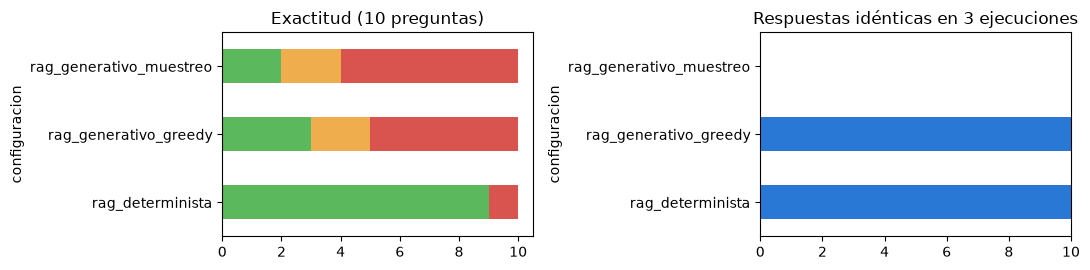

In [21]:
tabla = cmp.resumen(res_muestreo, res_greedy, res_det)
display(tabla)

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
tabla[["correcta", "parcial", "incorrecta"]].plot.barh(stacked=True, ax=axes[0], color=["#5cb85c", "#f0ad4e", "#d9534f"], legend=False)
axes[0].set_title("Exactitud (10 preguntas)"); axes[0].invert_yaxis()
tabla["repetibles"].plot.barh(ax=axes[1], color="#2a78d6"); axes[1].set_title("Respuestas idénticas en 3 ejecuciones")
axes[1].invert_yaxis(); axes[1].set_xlim(0, 10)
plt.tight_layout(); plt.savefig("../salidas/ej2_generativo_vs_determinista.png", dpi=120); plt.show()

In [22]:
# Trazabilidad: qué intención, parámetros y consulta respaldan cada respuesta determinista
pd.DataFrame([{k: v for k, v in responder_determinista(q).items() if k != "respuesta"} for q in banco.pregunta],
             index=banco.id)

,determinista,intencion,confianza,motivo,parametros,sparql
id,,,,,,
1,False,mejor_producto_categoria,0.52,confianza 0.52 < 0.55,NaN,NaN
2,True,productos_subcategoria_precio_max,0.82,NaN,"{'subcategoria': 'Smartwatches', 'precio_max': 1000}",SELECT ?nombre ?precio WHERE { ?p tv:nombre ?nombre ; tv:precio ?precio ; tv:perteneceA/rdfs:label ?subcat...
3,True,stock_bajo,0.89,NaN,{'umbral': 5},SELECT ?nombre ?stock WHERE { ?p a tv:Producto ; tv:nombre ?nombre ; tv:stock ?stock . FILTER(?stock < ?um...
4,True,promedio_categoria,0.93,NaN,{'categoria': 'Audio'},SELECT (AVG(?c) AS ?promedio) (COUNT(?p) AS ?total) WHERE { ?p tv:calificacionPromedio ?c ; tv:perteneceA/...
5,True,ventas_por_pais,0.90,NaN,{},SELECT ?pais (SUM(?t) AS ?ventas) WHERE { ?o a tv:Orden ; tv:total ?t ; tv:realizadaPor/tv:resideEn/rdfs:l...
6,False,pregunta_abierta,0.87,pregunta abierta,NaN,NaN
7,True,precio_producto,0.58,NaN,{'producto': 'Nintendo Switch OLED'},SELECT ?nombre ?precio WHERE { ?p tv:nombre ?producto ; tv:nombre ?nombre ; tv:precio ?precio }
8,True,resenas_negativas_pais,0.83,NaN,{'pais': 'Chile'},SELECT DISTINCT ?nombre WHERE { ?r a tv:ResenaEntrega ; tv:calificacion ?c ; tv:sobreProducto/tv:nombre ?n...
9,True,mejor_producto_categoria,0.60,NaN,{'categoria': 'Fotografia y Video'},SELECT ?nombre ?calificacion WHERE { ?p tv:nombre ?nombre ; tv:calificacionPromedio ?calificacion ; tv:per...


## Discusión

- **La ontología hace explícito el modelo de datos.** Las relaciones *orden → cliente → país* y
  *reseña → producto* quedan declaradas una vez y se consultan con caminos de propiedades; la
  jerarquía (`ResenaEntrega ⊑ Resena`) y la regla de riesgo producen conocimiento que no estaba en
  los CSV.
- **SHACL es control de calidad del scraping:** pandas aceptó un precio negativo y una calificación
  de 7★; las formas lo detectaron.
- **El RAG determinista acierta en lo que el RAG generativo no puede:** conteos, promedios, rankings
  y cruces. Y responde **lo mismo cada vez**, con la consulta como evidencia auditable.
- **Repetible no es lo mismo que correcto.** Con decodificación *greedy* el RAG generativo también
  repite su respuesta, pero repite el mismo error. Además esa repetibilidad se rompe en cuanto cambia
  el modelo, su versión o los documentos recuperados. La del RAG determinista depende solo de los
  datos y de la consulta.
- **Su límite es la cobertura:** solo responde intenciones previstas. Las preguntas abiertas pasan al
  *fallback* generativo, y el sistema lo dice (`[RAG]`).
- **El dato sigue siendo una foto:** el stock del DJI Air 3 sale de la ontología, construida con el
  scraping. Si la tienda vende unidades ahora, la respuesta queda desactualizada → Ejercicio 3.

## Reto opcional

1. Agregar la intención `clientes_por_pais` (*"¿cuántos clientes tiene la tienda en Colombia?"*):
   frases de ejemplo, parámetro `pais`, plantilla SPARQL y de respuesta. Verificar que el router la
   elige.
2. Agregar a la ontología la clase `tv:ProductoPopular` (≥ 15 unidades vendidas en `orden_items`) con
   una regla `CONSTRUCT`, y una forma SHACL que exija `tv:stock` en todo `tv:Producto`.
3. Bajar `UMBRAL` a 0.40: ¿qué preguntas abiertas pasan a responderse con una intención equivocada?